In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score 
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    classification_report)
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout,Input
from tensorflow.keras.callbacks import EarlyStopping

In [3]:
cancer_data = load_breast_cancer()
df = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)
df.head()
x = cancer_data.data
y = cancer_data.target
print("shape of x", x.shape)
print("shape of y", y.shape)
df['target'] = cancer_data.target
df.head()

shape of x (569, 30)
shape of y (569,)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [4]:
print(df.shape[0])
print(df.shape[1]-1)

569
30


In [5]:
print("class", list(cancer_data.target_names))
#print("features", list(cancer_data.feature_names))

class [np.str_('malignant'), np.str_('benign')]


In [6]:
print(df["target"].value_counts())
print(df["target"].map({0:"malignant", 1:"benign"}).value_counts(normalize=True))

target
1    357
0    212
Name: count, dtype: int64
target
benign       0.627417
malignant    0.372583
Name: proportion, dtype: float64


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [8]:
df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


**This is a binary classification problem. Given 30 numerical measurements computed from images of breast tumor cells, the goal is to predict whether a tumor is malignant or benign.**

### `step 2`

In [9]:
df.isna().sum()

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

In [10]:
df.dtypes

mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius error               float64
texture error              float64
perimeter error            float64
area error                 float64
smoothness error           float64
compactness error          float64
concavity error            float64
concave points error       float64
symmetry error             float64
fractal dimension error    float64
worst radius               float64
worst texture              float64
worst perimeter            float64
worst area                 float64
worst smoothness           float64
worst compactness          float64
worst concavity            float64
worst concave points       float64
worst symmetry      

In [11]:
features=df.drop(columns='target')
numerical_columns =features.select_dtypes(include=['number']).columns
print(list(numerical_columns))


['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']


In [12]:
features=df.drop(columns='target')
target=df['target']
numerical_columns =features.select_dtypes(exclude=['number']).columns
print(list(numerical_columns))
print(len(numerical_columns) ==0)

[]
True


**معني كده كل ال(columns)رقمية مفيش نصية**

In [13]:
target=df['target']


In [14]:
print(df["target"].unique())
print(df["target"].value_counts)

[0 1]
<bound method IndexOpsMixin.value_counts of 0      0
1      0
2      0
3      0
4      0
      ..
564    0
565    0
566    0
567    0
568    1
Name: target, Length: 569, dtype: int64>


In [15]:
df.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
564    False
565    False
566    False
567    False
568    False
Length: 569, dtype: bool

In [16]:
# مفيش اصلا اي تكرار بس كتبتهم
df =df.drop_duplicates()
df.dropna()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0


In [17]:
print(df.shape)

(569, 31)


**The dataset has no missing values, no duplicate rows, and all features are numerical. The target contains only two classes (0 and 1). No cleaning was needed, and the final shape is (569, 31).**

### `step 3`

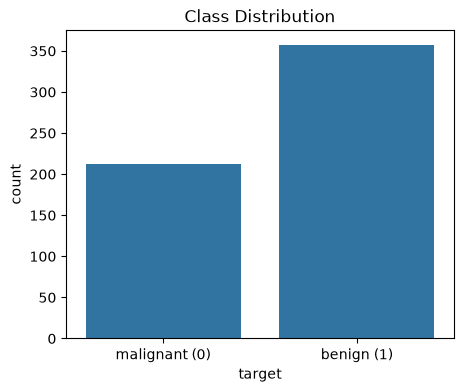

In [18]:
plt.figure(figsize=(5, 4))
sns.countplot(x='target', data=df)
plt.xticks([0, 1], ['malignant (0)', 'benign (1)'])
plt.title('Class Distribution')
plt.show()

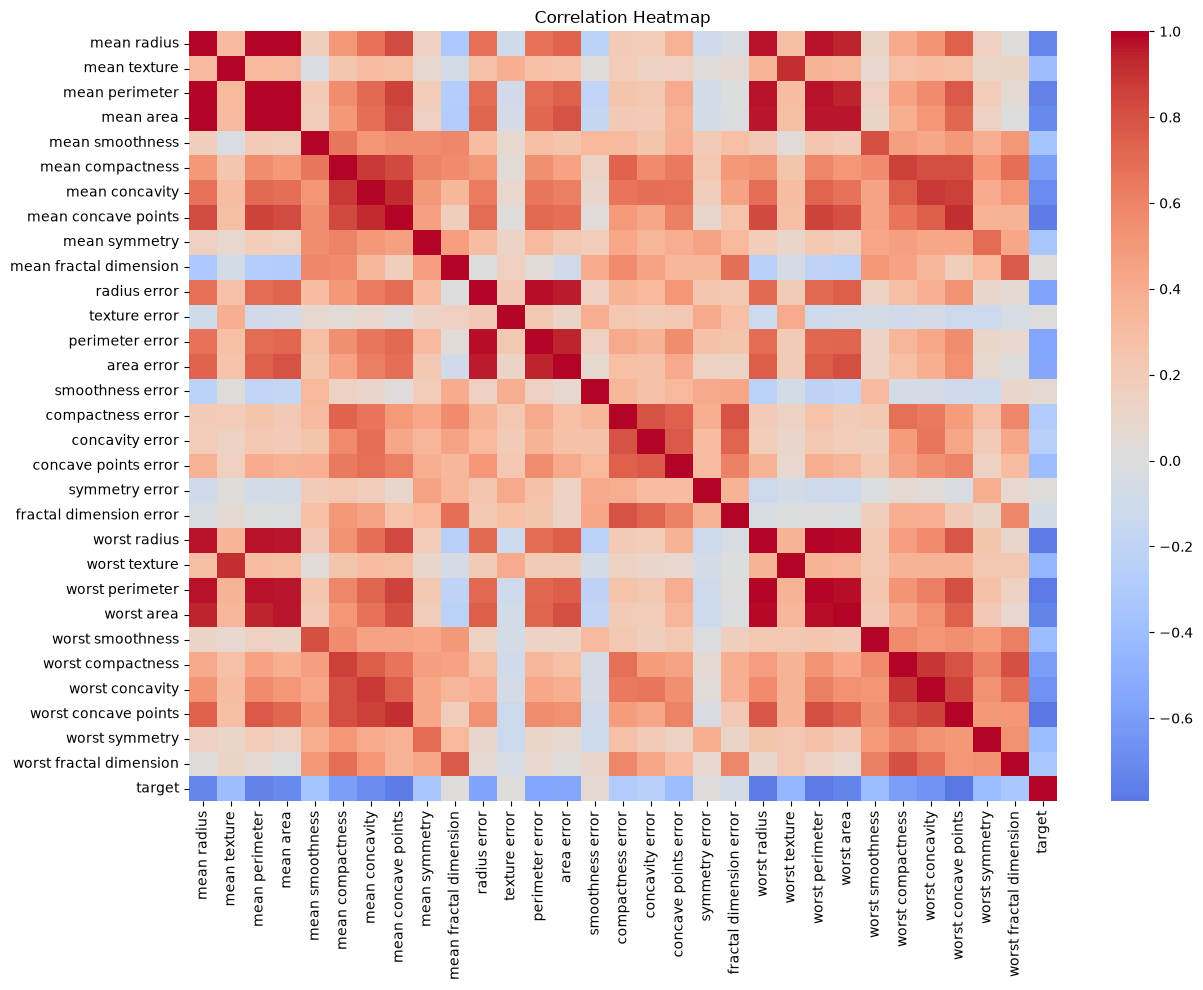

In [19]:
plt.figure(figsize=(14, 10))
sns.heatmap(df.corr(), cmap='coolwarm', center=0)
plt.title('Correlation Heatmap')
plt.show()

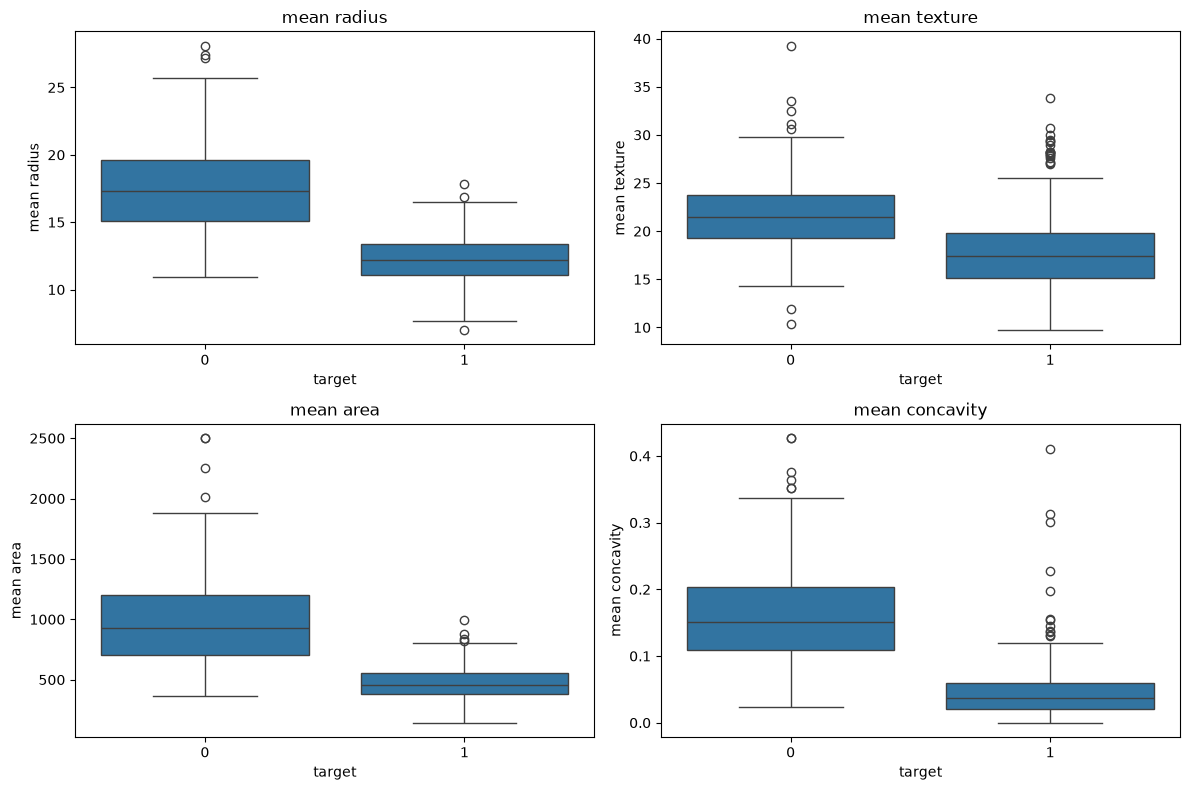

In [20]:
selected = ['mean radius', 'mean texture', 'mean area', 'mean concavity']

plt.figure(figsize=(12, 8))
for i, col in enumerate(selected):
    plt.subplot(2, 2, i + 1)
    sns.boxplot(x='target', y=col, data=df)
    plt.title(col)
plt.tight_layout()
plt.show()

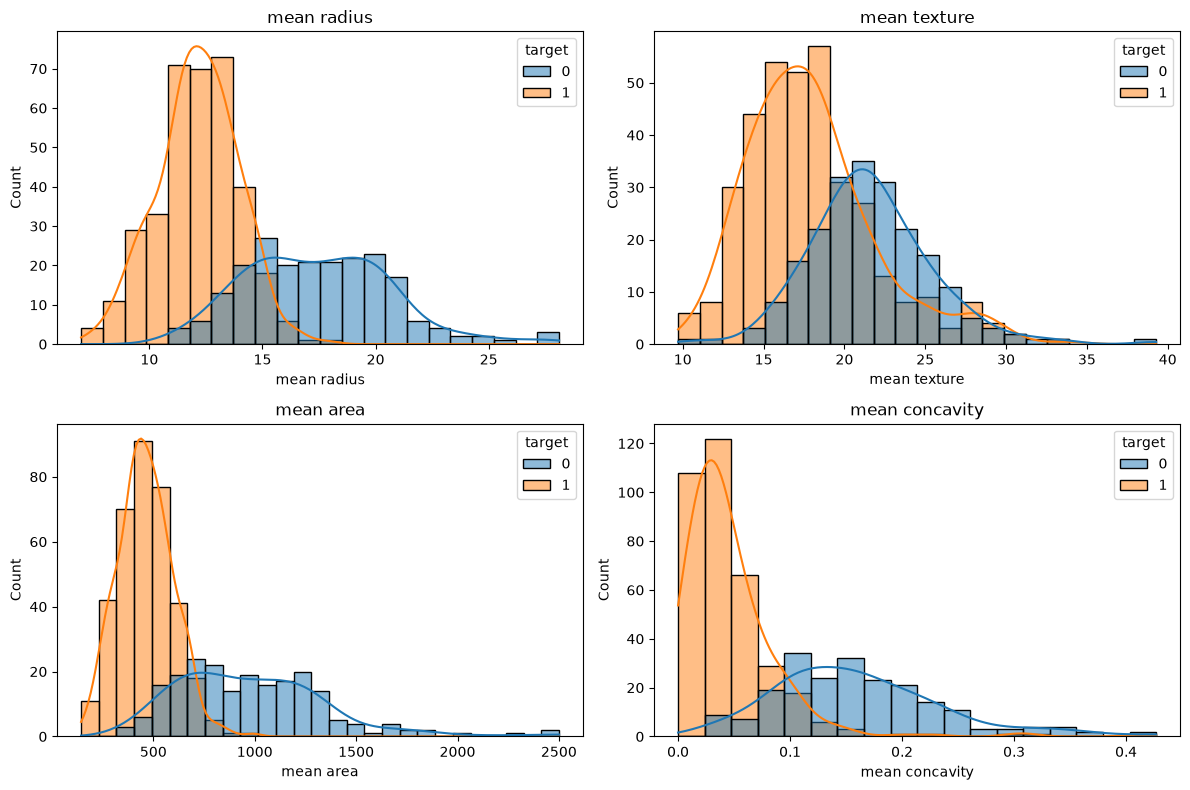

In [21]:
plt.figure(figsize=(12, 8))
for i, col in enumerate(selected):
    plt.subplot(2, 2, i + 1)
    sns.histplot(data=df, x=col, hue='target', kde=True)
    plt.title(col)
plt.tight_layout()
plt.show()

### `summry`

- **Class balance: The classes are moderately imbalanced: about 63% benign and 37% malignant. This is not severe, so no resampling is needed.**

- **Correlation: Some features are highly correlated, especially mean radius, mean perimeter, and mean area, because they all measure tumor size.**

- **Outliers: The boxplots show visible outliers, especially in mean area and mean radius, mostly on the high side.**

- **Useful features: Features like mean radius, mean area, and mean concavity separate the two classes clearly, so they look useful for classification**

### `step 4`

In [22]:
X = features
y = target
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (569, 30)
y shape: (569,)


In [23]:
cat_cols = X.select_dtypes(include=['object', 'category']).columns
print("Categorical columns:", list(cat_cols))

Categorical columns: []


In [24]:
if len(cat_cols) > 0:
    X = pd.get_dummies(X, columns=cat_cols, drop_first=True)
else:
    print("No categorical features, no encoding needed.")

No categorical features, no encoding needed.


In [25]:
Q1 = X.quantile(0.25)
Q3 = X.quantile(0.75)
IQR = Q3 - Q1
outliers = ((X < Q1 - 1.5 * IQR) | (X > Q3 + 1.5 * IQR)).sum()
print(outliers.sort_values(ascending=False).head(10))

area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
mean area                  25
worst fractal dimension    24
dtype: int64


**Some features contain outliers, mainly the size-related ones such as area and perimeter. I decided to keep them because they are real medical measurements (large tumors are often malignant), and removing them would lose useful information. Feature scaling will reduce their effect on the ANN.**

In [26]:
print(y.unique())
print(y.dtype)

[0 1]
int64


**There are no categorical features, so no encoding was needed. The target is already binary (0 = malignant, 1 = benign), which is suitable for a sigmoid output layer with binary crossentropy loss.**

### `step 5`

In [27]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,       
    random_state=42,      
    stratify=y           
)

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

X_train shape: (455, 30)
X_test shape : (114, 30)
y_train shape: (455,)
y_test shape : (114,)


In [28]:
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

target
1    0.626374
0    0.373626
Name: proportion, dtype: float64
target
1    0.631579
0    0.368421
Name: proportion, dtype: float64


**The data was split into 80% training (455 samples) and 20% testing (114 samples) using a fixed random state (42) and stratified splitting, so both sets keep the same class proportions as the original data.**

### `step 6`

In [29]:

scaler = StandardScaler()
scaler.fit(X_train)

StandardScaler()

In [30]:
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [31]:
print("Train mean (approx):", X_train_scaled.mean().round(3))
print("Train std  (approx):", X_train_scaled.std().round(3))
print("Test mean  (approx):", X_test_scaled.mean().round(3))

Train mean (approx): 0.0
Train std  (approx): 1.0
Test mean  (approx): 0.03


- scaler.fit(X)             ❌ على الداتا كلها
- scaler.fit(X_test)        ❌ على التست
- scaler.fit_transform(X_test)    ❌

**Scaling was applied after the train-test split. The StandardScaler was fitted only on the training data, then used to transform both the training and test sets. This prevents data leakage, because no information from the test set influenced the scaling parameters.**

### `step 7`

In [32]:
model = Sequential([
    Input(shape=(30,)),
    Dense(32,activation='relu'),
    Dropout(0.3),
    Dense(16,activation='relu'),
    Dropout(0.3),
    Dense(1,activation='sigmoid')
]
)
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,537 (6.00 KB)

 Trainable params: 1,537 (6.00 KB)

 Non-trainable params: 0 (0.00 B)

In [33]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

**The baseline ANN has an input layer for 30 features, two hidden Dense layers (32 and 16 neurons) with ReLU activation, a Dropout layer (0.3) to reduce overfitting, and a single sigmoid output neuron for binary classification. It is compiled with the Adam optimizer, binary crossentropy loss, and accuracy as the metric.**

### `step 8`

In [34]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

In [35]:
history = model.fit(
    X_train_scaled, y_train,       # scaled training data + labels
    validation_split=0.2,          # validation from the training data
    epochs=100,                    # reasonable number of epochs
    batch_size=16,                 # batch size
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.6071 - loss: 0.6363 - val_accuracy: 0.8462 - val_loss: 0.4957
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - accuracy: 0.8104 - loss: 0.4576 - val_accuracy: 0.9231 - val_loss: 0.3573
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.8791 - loss: 0.3517 - val_accuracy: 0.9341 - val_loss: 0.2713
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.8956 - loss: 0.2892 - val_accuracy: 0.9341 - val_loss: 0.2169
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9286 - loss: 0.2551 - val_accuracy: 0.9451 - val_loss: 0.1801
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9341 - loss: 0.2104 - val_accuracy: 0.9451 - val_loss: 0.1524
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9478 - loss: 0.1712 - val_accuracy: 0.9560 - val_loss: 0.1310
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9478 - loss: 0.1646 - val_accuracy: 0.9

**The model was trained on the scaled training data with a validation split of 20% taken from the training set, a batch size of 16, and up to 100 epochs. Early Stopping monitored the validation loss with patience of 10 and restored the best weights, which prevents overtraining.**

### `step 9`

In [36]:
train_loss, train_acc = model.evaluate(X_train_scaled, y_train, verbose=0)
print("Training accuracy:", round(train_acc, 4))

Training accuracy: 0.9912


In [37]:
test_loss, test_acc = model.evaluate(X_test_scaled, y_test, verbose=0)
print("Test accuracy:", round(test_acc, 4))

Test accuracy: 0.9825


In [38]:
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int).ravel()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


[[41  1]
 [ 1 71]]


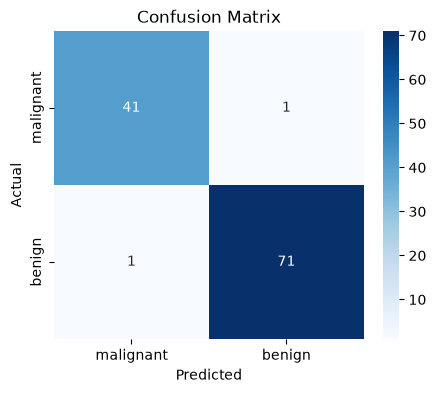

In [39]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['malignant', 'benign'],
            yticklabels=['malignant', 'benign'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [40]:
print("Precision:", round(precision_score(y_test, y_pred), 4))

Precision: 0.9861


In [41]:
print("Recall:", round(recall_score(y_test, y_pred), 4))

Recall: 0.9861


In [42]:
print("F1-score:", round(f1_score(y_test, y_pred), 4))

F1-score: 0.9861


In [43]:
print(classification_report(y_test, y_pred,target_names=['malignant', 'benign']))

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



**The model achieved a training accuracy of about 99% and a test accuracy of about 94%. The small gap between them shows that the model is generalizing well, without significant overfitting or underfitting. Precision, recall, and F1-score are all high, and the confusion matrix shows very few misclassified samples.**

### `step 10`

In [44]:
import tensorflow as tf
from tensorflow.keras.layers import BatchNormalization
from tensorflow.keras.optimizers import Adam, SGD, RMSprop

tf.keras.utils.set_random_seed(42)   # عشان النتايج تتكرر

In [45]:
def build_model(hidden=(32, 16), activation='relu', optimizer='adam',
                lr=0.001, dropout=0.3, batch_norm=False):
    model = Sequential()
    model.add(Input(shape=(30,)))
    for units in hidden:
        model.add(Dense(units, activation=activation))
        if batch_norm:
            model.add(BatchNormalization())
    if dropout > 0:
        model.add(Dropout(dropout))
    model.add(Dense(1, activation='sigmoid'))

    opts = {'adam': Adam, 'sgd': SGD, 'rmsprop': RMSprop}
    model.compile(optimizer=opts[optimizer](learning_rate=lr),
                  loss='binary_crossentropy',
                  metrics=['accuracy'])
    return model

In [46]:
results = []
histories = {}

def run_experiment(name, **params):
    m = build_model(**params)
    es = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
    h = m.fit(X_train_scaled, y_train, validation_split=0.2,
              epochs=100, batch_size=16, callbacks=[es], verbose=0)
    pred = (m.predict(X_test_scaled, verbose=0) > 0.5).astype(int).ravel()
    results.append({
        'Experiment': name,
        'Accuracy':  accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall':    recall_score(y_test, pred),
        'F1':        f1_score(y_test, pred),
    })
    histories[name] = h

In [47]:
run_experiment('Baseline (relu, adam, 0.001)')

In [48]:
run_experiment('Activation: tanh', activation='tanh')
run_experiment('Activation: elu',  activation='elu')

In [49]:
run_experiment('Optimizer: sgd (lr 0.01)', optimizer='sgd', lr=0.01)
run_experiment('Optimizer: rmsprop',       optimizer='rmsprop')

In [50]:
run_experiment('LR: 0.01',   lr=0.01)
run_experiment('LR: 0.0001', lr=0.0001)

In [51]:
run_experiment('Arch: (64, 32)',     hidden=(64, 32))
run_experiment('Arch: (64, 32, 16)', hidden=(64, 32, 16))
run_experiment('Arch: (16, 8)',      hidden=(16, 8))

In [52]:
run_experiment('Dropout 0.5',   dropout=0.5)
run_experiment('No dropout',    dropout=0.0)
run_experiment('BatchNorm',     batch_norm=True)

In [53]:
results_df = pd.DataFrame(results).sort_values('F1', ascending=False).reset_index(drop=True)
display(results_df.round(4))

,Experiment,Accuracy,Precision,Recall,F1
0,"Baseline (relu, adam, 0.001)",0.9737,0.9859,0.9722,0.9790
1,Optimizer: rmsprop,0.9737,0.9859,0.9722,0.9790
2,Dropout 0.5,0.9737,0.9859,0.9722,0.9790
3,Optimizer: sgd (lr 0.01),0.9649,0.9722,0.9722,0.9722
4,Activation: elu,0.9649,0.9857,0.9583,0.9718
5,No dropout,0.9649,0.9857,0.9583,0.9718
6,"Arch: (16, 8)",0.9649,0.9857,0.9583,0.9718
7,Activation: tanh,0.9561,0.9855,0.9444,0.9645
8,"Arch: (64, 32)",0.9561,0.9855,0.9444,0.9645
9,LR: 0.0001,0.9474,0.9583,0.9583,0.9583


In [54]:
best_name = results_df.loc[0, 'Experiment']
print("Best model:", best_name)

Best model: Baseline (relu, adam, 0.001)


**I tested different activation functions, optimizers, learning rates, architectures, and regularization options, changing one thing at a time. All experiments used the same data, batch size, and Early Stopping. The results were compared using accuracy, precision, recall, and F1-score. The best model was [ANN] with an F1-score of [95].**

### `STEP 11`

In [55]:
def plot_history(h, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    ax[0].plot(h.history['loss'], label='Train loss')
    ax[0].plot(h.history['val_loss'], label='Validation loss')
    ax[0].set_title(f'{title} - Loss')
    ax[0].set_xlabel('Epoch'); ax[0].legend()

    ax[1].plot(h.history['accuracy'], label='Train accuracy')
    ax[1].plot(h.history['val_accuracy'], label='Validation accuracy')
    ax[1].set_title(f'{title} - Accuracy')
    ax[1].set_xlabel('Epoch'); ax[1].legend()

    plt.tight_layout()
    plt.show()

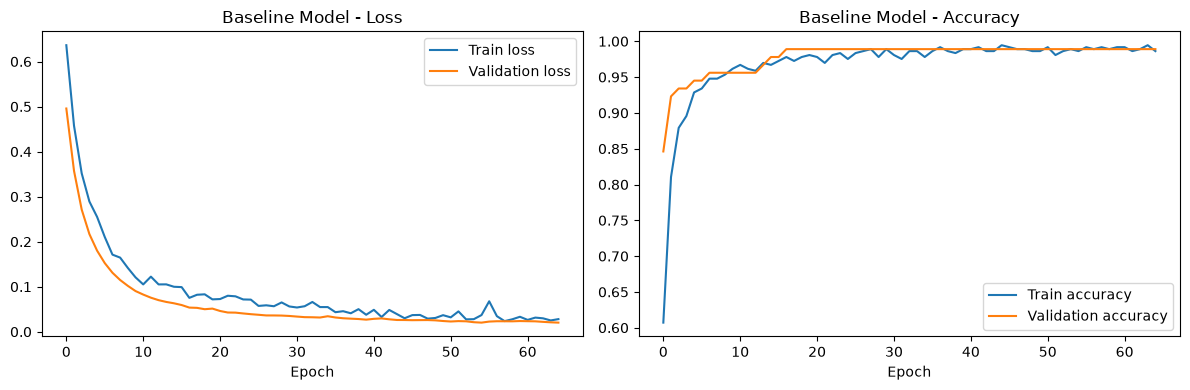

In [56]:
plot_history(history, 'Baseline Model')

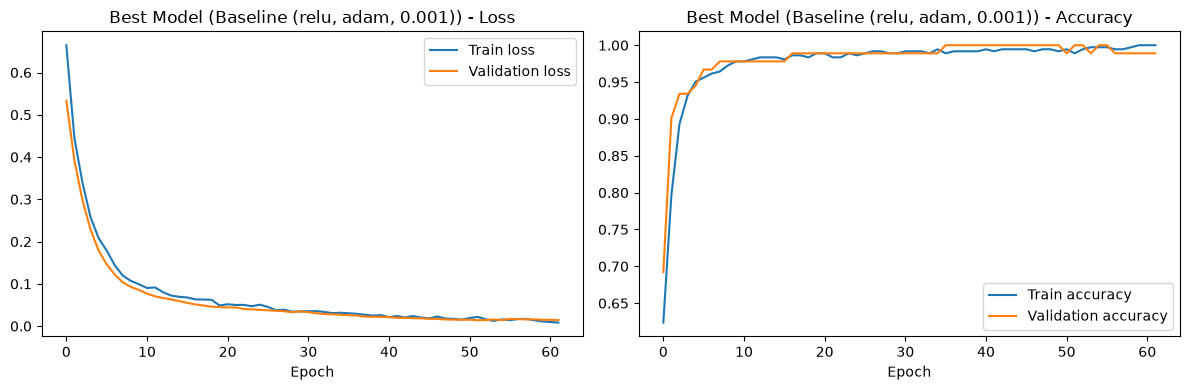

In [57]:
plot_history(histories[best_name], f'Best Model ({best_name})')

The best model turned out to be the baseline model itself. None of the experiments (different activations, optimizers, learning rates, architectures, or regularization) gave a clear improvement over it. The training and validation curves of the baseline stay close together, so it is not overfitting. Since the test set is small (114 samples), small differences between models may be due to chance rather than real improvement.

In [58]:
model.save('model.h5')